In [93]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
pd.options.display.float_format = '{:.5f}'.format

In [94]:
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

## Import Data

In [95]:
# Load files
train = pd.read_csv('train.csv')
policies = pd.read_csv('policies.csv')
test = pd.read_csv('test.csv')
samplesubmission = pd.read_csv('SampleSubmission.csv')

In [96]:
train.head()

,claim_id,policy_number,claim_number,sum_insured,product,agent,class_of_business,risk_type,loss_date,client_type,renewal_frequency,primary_cause,secondary_cause,branch,target
0,ID_JZ7QWRHH57RO,pol000009680,claim0011359,300000.00000,prod00027,ag00068,cob00031,rt00006,2021-05-13,ct0003,rf0001,pc0007,sc00022,br00006,82150.00000
1,ID_KQ5TJMVLJ4EP,pol000006869,claim0005272,16000.00000,prod00005,ag00226,cob00010,rt00032,2018-05-13,ct0003,rf0001,pc0007,sc00023,br00002,3780.24000
2,ID_NYHI7WJGGIAE,pol000006135,claim0004147,3000.00000,prod00029,ag00037,cob00010,rt00026,2018-08-18,ct0003,rf0001,pc0007,sc00024,br00002,2196.50000
3,ID_ROMMDCXYUXN5,pol000008991,claim0009962,6000.00000,prod00005,ag00037,cob00009,rt00032,2018-12-20,ct0003,rf0001,pc0007,sc00021,br00001,105.67000
4,ID_2OTD9NX8L73D,pol000007768,claim0007346,26850.00000,prod00015,ag00226,cob00034,rt00023,2018-11-07,ct0001,rf0001,pc0007,sc00021,br00001,1605.64000


## Correlation between qualitative variables

In [97]:
cat_cols = train.columns.difference(['claim_id', 'loss_date', 'sum_insured', 'target']).tolist()
train[cat_cols].head()

,agent,branch,claim_number,class_of_business,client_type,policy_number,primary_cause,product,renewal_frequency,risk_type,secondary_cause
0,ag00068,br00006,claim0011359,cob00031,ct0003,pol000009680,pc0007,prod00027,rf0001,rt00006,sc00022
1,ag00226,br00002,claim0005272,cob00010,ct0003,pol000006869,pc0007,prod00005,rf0001,rt00032,sc00023
2,ag00037,br00002,claim0004147,cob00010,ct0003,pol000006135,pc0007,prod00029,rf0001,rt00026,sc00024
3,ag00037,br00001,claim0009962,cob00009,ct0003,pol000008991,pc0007,prod00005,rf0001,rt00032,sc00021
4,ag00226,br00001,claim0007346,cob00034,ct0001,pol000007768,pc0007,prod00015,rf0001,rt00023,sc00021


In [98]:
from scipy.stats import chi2_contingency

In [99]:
table = pd.crosstab(train.renewal_frequency, train.secondary_cause)

result = chi2_contingency(table)
print("Statistique de Test:", result[0])
print("P-value", result[1])

Statistique de Test: 1082.4517270623069
P-value 3.2948537737044444e-91


In [100]:
np.corrcoef(train.target, train.sum_insured)

array([[1.        , 0.10260407],
       [0.10260407, 1.        ]])

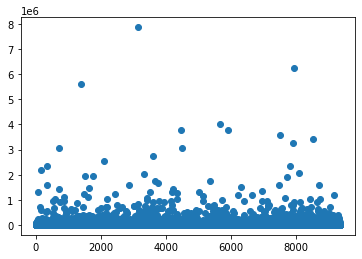

In [101]:
plt.scatter(range(train.shape[0]),train.target)

(5780,)


<AxesSubplot:xlabel='target', ylabel='Density'>

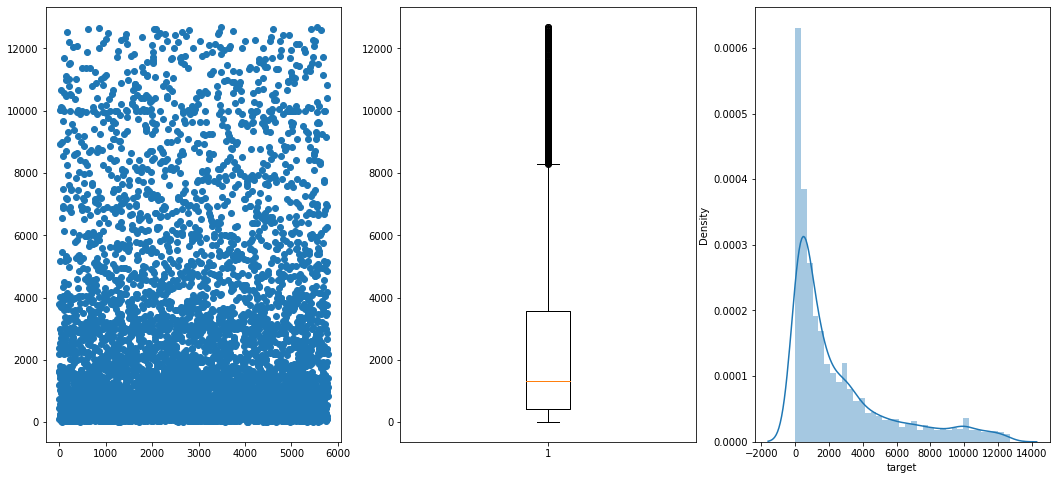

In [102]:
seuil = np.quantile(train.target, 0.75)
X=train.target[(train.target<seuil) & (train.target>0)]
print(X.shape)
plt.figure(figsize=(18,8))
plt.subplot(1,3,1)
plt.scatter(range(X.shape[0]),X)
plt.subplot(1,3,2)
plt.boxplot(X)
plt.subplot(1,3,3)
sns.distplot(X)

In [103]:
train_cat = []
for i in train.target:
    if i<=2000:
        train_cat.append("Nothing")
    if i>2000 and i<=12000:
        train_cat.append("Mean")
    if i>12000:
        train_cat.append("Xtra")

train["target_cat"] = train_cat

In [104]:
train.head()

,claim_id,policy_number,claim_number,sum_insured,product,agent,class_of_business,risk_type,loss_date,client_type,renewal_frequency,primary_cause,secondary_cause,branch,target,target_cat
0,ID_JZ7QWRHH57RO,pol000009680,claim0011359,300000.00000,prod00027,ag00068,cob00031,rt00006,2021-05-13,ct0003,rf0001,pc0007,sc00022,br00006,82150.00000,Xtra
1,ID_KQ5TJMVLJ4EP,pol000006869,claim0005272,16000.00000,prod00005,ag00226,cob00010,rt00032,2018-05-13,ct0003,rf0001,pc0007,sc00023,br00002,3780.24000,Mean
2,ID_NYHI7WJGGIAE,pol000006135,claim0004147,3000.00000,prod00029,ag00037,cob00010,rt00026,2018-08-18,ct0003,rf0001,pc0007,sc00024,br00002,2196.50000,Mean
3,ID_ROMMDCXYUXN5,pol000008991,claim0009962,6000.00000,prod00005,ag00037,cob00009,rt00032,2018-12-20,ct0003,rf0001,pc0007,sc00021,br00001,105.67000,Nothing
4,ID_2OTD9NX8L73D,pol000007768,claim0007346,26850.00000,prod00015,ag00226,cob00034,rt00023,2018-11-07,ct0001,rf0001,pc0007,sc00021,br00001,1605.64000,Nothing


In [105]:
train.target_cat.value_counts()/train.shape[0]

Nothing   0.50363
Xtra      0.25597
Mean      0.24040
Name: target_cat, dtype: float64

<AxesSubplot:ylabel='target_cat'>

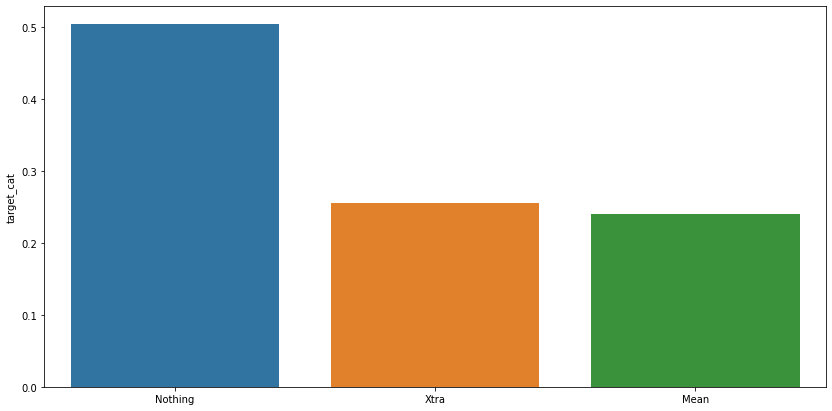

In [106]:
plt.figure(figsize=(14,7))
sns.barplot(train.target_cat.value_counts().index,(train.target_cat.value_counts()/train.shape[0]))

In [107]:
obj_feat = list(train.loc[:, train.dtypes == 'object'].columns.values)
for feature in obj_feat:
    train[feature] = pd.Series(train[feature], dtype="category")

In [108]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9376 entries, 0 to 9375
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   claim_id           9376 non-null   category
 1   policy_number      9290 non-null   category
 2   claim_number       9376 non-null   category
 3   sum_insured        9376 non-null   float64 
 4   product            9376 non-null   category
 5   agent              9376 non-null   category
 6   class_of_business  9376 non-null   category
 7   risk_type          9376 non-null   category
 8   loss_date          9376 non-null   category
 9   client_type        9376 non-null   category
 10  renewal_frequency  9376 non-null   category
 11  primary_cause      9376 non-null   category
 12  secondary_cause    9376 non-null   category
 13  branch             9376 non-null   category
 14  target             9376 non-null   float64 
 15  target_cat         9376 non-null   category
dtypes: cat

In [109]:
train[cat_cols] = train[cat_cols].apply(lambda x: x.fillna(x.value_counts().index[0]))

In [110]:
pd.Series(train.target_cat).value_counts().sort_values(ascending=False)

Nothing    4722
Xtra       2400
Mean       2254
Name: target_cat, dtype: int64

In [113]:
# Convert datetime variables to datetime objects
train.loss_date = pd.to_datetime(train.loss_date, errors='coerce')

# Fill in missing values in categorical variables with the most common
train[cat_cols] = train[cat_cols].apply(lambda x: x.fillna(x.value_counts().index[0]))

# Extract day, month and year from the loss date column
train['loss_date_day'] = train.loss_date.dt.day #day

train['loss_date_month'] = train.loss_date.dt.month #month
 
train['loss_date_year'] = train.loss_date.dt.year #year

#convert
main_cols = train.columns.difference(['claim_id', 'loss_date', 'target', "target_cat"]).tolist()
X = train[main_cols]
y = train.target_cat
dict={j:i for i,j in enumerate(y.value_counts().sort_values(ascending=False).index)}
y=[dict[i] for i in y]

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3, random_state=0)

In [114]:
params = {'task': 'train',
    'boosting_type': 'gbdt',
    'objective': 'multiclass',
    'num_class':3,
    'metric': 'multi_logloss',
    'learning_rate': 0.001,
    'max_depth': 7,
    'num_leaves': 15,
    'feature_fraction': 0.4,
    'bagging_fraction': 0.6,
    'bagging_freq': 20,
    'verbose':0}

In [115]:
d_train = lgbm.Dataset(X_train, y_train)

lgb_cv = lgbm.cv(params, d_train, num_boost_round=10000, nfold=5, shuffle=True, stratified=True)

nround = lgb_cv['multi_logloss-mean'].index(np.min(lgb_cv['multi_logloss-mean']))

[LightGBM] [Warning] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000914 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Warning] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000954 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Warning] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000972 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Warning] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000974 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Warning] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000918 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

In [116]:
model = lgbm.train(params, d_train, num_boost_round=nround)

[LightGBM] [Warning] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001315 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM]

In [117]:
from sklearn.metrics import classification_report

In [118]:
pred=model.predict(X_test)
pred=[np.argmax(i) for i in pred]
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

           0       0.71      0.83      0.77      1413
           1       0.73      0.78      0.75       742
           2       0.51      0.29      0.37       658

    accuracy                           0.69      2813
   macro avg       0.65      0.63      0.63      2813
weighted avg       0.67      0.69      0.67      2813



In [119]:
# Convert datetime variables to datetime objects
test.loss_date = pd.to_datetime(test.loss_date, errors='coerce')

# Fill in missing values in categorical variables with the most common
test[cat_cols] = test[cat_cols].apply(lambda x: x.fillna(x.value_counts().index[0]))

# Convert
obj_feat = list(test.loc[:, test.dtypes == 'object'].columns.values)
for feature in obj_feat:
    test[feature] = pd.Series(test[feature], dtype="category")

# Extract day, month and year from the loss date column
test['loss_date_day'] = test.loss_date.dt.day #day

test['loss_date_month'] = test.loss_date.dt.month #month
 
test['loss_date_year'] = test.loss_date.dt.year #year


In [120]:
import lightgbm as lgb

In [121]:
hyper_params = {
    'task': 'train',
    'boosting_type': 'gbdt',
    'objective': 'regression',
    'metric': ['l1'],
    'learning_rate': 0.005,
    "num_leaves": 128,  
    "max_bin": 512,
}

In [122]:
train.head()

,claim_id,policy_number,claim_number,sum_insured,product,agent,class_of_business,risk_type,loss_date,client_type,renewal_frequency,primary_cause,secondary_cause,branch,target,target_cat,loss_date_day,loss_date_month,loss_date_year
0,ID_JZ7QWRHH57RO,pol000009680,claim0011359,300000.00000,prod00027,ag00068,cob00031,rt00006,2021-05-13,ct0003,rf0001,pc0007,sc00022,br00006,82150.00000,Xtra,13,5,2021
1,ID_KQ5TJMVLJ4EP,pol000006869,claim0005272,16000.00000,prod00005,ag00226,cob00010,rt00032,2018-05-13,ct0003,rf0001,pc0007,sc00023,br00002,3780.24000,Mean,13,5,2018
2,ID_NYHI7WJGGIAE,pol000006135,claim0004147,3000.00000,prod00029,ag00037,cob00010,rt00026,2018-08-18,ct0003,rf0001,pc0007,sc00024,br00002,2196.50000,Mean,18,8,2018
3,ID_ROMMDCXYUXN5,pol000008991,claim0009962,6000.00000,prod00005,ag00037,cob00009,rt00032,2018-12-20,ct0003,rf0001,pc0007,sc00021,br00001,105.67000,Nothing,20,12,2018
4,ID_2OTD9NX8L73D,pol000007768,claim0007346,26850.00000,prod00015,ag00226,cob00034,rt00023,2018-11-07,ct0001,rf0001,pc0007,sc00021,br00001,1605.64000,Nothing,7,11,2018


In [132]:
np.quantile(y1.to_list(),0.55)

60577.516

In [123]:
train_Xtra = train[train.target_cat=="Xtra"]
train_Mean = train[train.target_cat=="Mean"]
X1=train_Xtra[main_cols]
y1=train_Xtra.target
X2=train_Mean[main_cols]
y2=train_Mean.target
lgb_train_1 = lgb.Dataset(X1, y1)
lgb_train_2 = lgb.Dataset(X2, y2)
regressor_Xtra = lgb.train(hyper_params, lgb_train_1, num_boost_round=1000, verbose_eval=False)
regressor_Mean = lgb.train(hyper_params, lgb_train_2, num_boost_round=1000, verbose_eval=False)

[LightGBM] [Warning] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000497 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 888
[LightGBM] [Info] Number of data points in the train set: 2400, number of used features: 15
[LightGBM] [Info] Start training from score 156024.985711
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive

(549, 16)
(1134, 16)
4019
(1134,)
(549,)


Text(0.5, 1.0, 'Predictions Data Distribution')

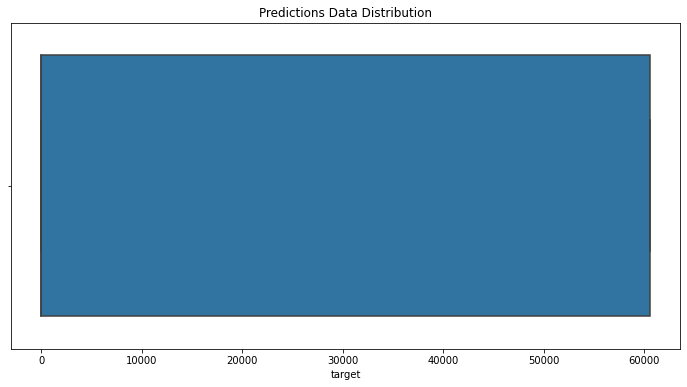

In [134]:
# Make prediction on the test set
obj_feat = list(test.loc[:, test.dtypes == 'object'].columns.values)
for feature in obj_feat:
    test[feature] = pd.Series(test[feature], dtype="category")

test_df = test[main_cols]

pred=model.predict(test_df)
pred=[np.argmax(i) for i in pred]
inv_dict={j:i for i,j in dict.items()}
cat = [inv_dict[i] for i in pred]

test_df["target_cat"]=cat

predictions = [0]*test_df.shape[0]
print(train_Mean.shape)
print(train_Xtra.shape)
print(len(predictions))
train_Xtra = test_df[test_df.target_cat=="Xtra"]
train_Mean = test_df[test_df.target_cat=="Mean"]
X1=train_Xtra[main_cols]
X2=train_Mean[main_cols]

pred1=regressor_Xtra.predict(X1)
pred2=regressor_Mean.predict(X2)
print(pred1.shape)
print(pred2.shape)
for i,j in zip(train_Xtra.index, pred1):
    predictions[i]=np.quantile(y1.to_list(),0.55)
for i,j in zip(train_Mean.index, pred2):
    predictions[i]=j

#predictions = [np.abs(i) for i in predictions]
# # Create a submission file
sub_file = samplesubmission.copy()
sub_file.target = predictions

# Check the distribution of your predictions
plt.figure(figsize=(12, 6))
sns.boxplot(sub_file.target)
plt.title('Predictions Data Distribution')

In [128]:
# Write to csv file to submit to Zindi
sub_file.to_csv("submit4.csv", index = False)